In [ ]:
import os
import sys

import joblib
import itertools
import pandas as pd
import numpy as np
from sklearn.svm import OneClassSVM

sys.path.insert(0, '../../..') 
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.helper_functions import load_outlier_data
from utils.constants import Configs
from utils.loso_models.ocsvm_detector import OCSVMDetector
from utils.loso_pipeline import run_loso_evaluation
from utils.metrics import movement_level_confusion
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.dtw_radius import load_dtw_matrices

TARGET_MOVEMENT = 'Park'
ALGORITHM_NAME = 'OCSVM'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True

In [9]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)
df = df.sort_values(by=Configs.KEYS + ['step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

In [10]:
# Metadata: one line per movement, same order as the matrices
results_temp_base = df_filtered[Configs.KEYS].drop_duplicates().reset_index(drop=True)
n_movements = len(results_temp_base)

In [11]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, _  = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, _ = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)

def prep_gt(gt, phase):
    """
    Prepare the ground truth data for a specific phase.
    """
    gt = gt[gt['movLabel'] == phase] if 'movLabel' in gt.columns else gt
    return gt.drop_duplicates(subset=Configs.KEYS).reset_index(drop=True)

gt_left  = prep_gt(outliers_left_csv,  TARGET_MOVEMENT)
gt_right = prep_gt(outliers_right_csv, TARGET_MOVEMENT)
gt_union = (pd.concat([gt_left, gt_right])
              .drop_duplicates(subset=Configs.KEYS).reset_index(drop=True))

GT = {'L': gt_left, 'R': gt_right, 'OR': gt_union}
for k, g in GT.items():
    print(f"GT {k}: {len(g)} positivos / {n_movements} movimentos = {len(g)/n_movements*100:.2f}%")

# All positive samples must exist in the metadata
base_keys = set(map(tuple, results_temp_base[Configs.KEYS].values))
for k, g in GT.items():
    missing = [t for t in map(tuple, g[Configs.KEYS].values) if t not in base_keys]
    assert not missing, f"GT {k}: {len(missing)} positivos sem movimento correspondente"


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
GT L: 1 positivos / 185 movimentos = 0.54%
GT R: 3 positivos / 185 movimentos = 1.62%
GT OR: 4 positivos / 185 movimentos = 2.16%


In [12]:
# group_array = [
#     'xs_L', 'ys_L', 'zs_L', 'xe_L', 'ye_L', 'ze_L', 'xw_L', 'yw_L', 'zw_L', # Braço Esquerdo
#     'xs_R', 'ys_R', 'zs_R', 'xe_R', 'ye_R', 'ze_R', 'xw_R', 'yw_R', 'zw_R'  # Braço Direito
# ]
group_array = [
    'x_L', 'y_L', 'z_L', # Left Arm
    'x_R', 'y_R', 'z_R' # Right Arm
]
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, 18)

Processing time series: 100%|██████████| 185/185 [00:00<00:00, 2807.33it/s]

Shape of first series: (46, 6)


Shape of formatted series: (185, 466, 6)


## One Class SVM

In [ ]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

n_positives = {k: len(g) for k, g in GT.items()}

def get_base_vars(gt_key: str) -> tuple:
    gt_used = GT[gt_key]

    # Ground truth used for evalution on this run
    total_known_outliers = len(gt_used)

    # Movement-level anomalies
    known_outlier_rate = total_known_outliers / n_movements if n_movements > 0 else 0.0
    known_percentage = known_outlier_rate * 100
    
    # print(f"GT used ({"Union"}): {total_known_outliers} positives / {n_movements} movements = {known_percentage:.2f}%")
    return gt_used, total_known_outliers, known_percentage


# Sincronization: series matrix (X_movement) and DTW matrix must have the same number of rows as the metadata
if X_movement.shape[0] != n_movements:
    raise ValueError(f"X_movement ({X_movement.shape[0]}) != metadata ({n_movements})")
# if dtw_matrix.shape[0] != n_movements:
    # raise ValueError(f"DTW ({dtw_matrix.shape[0]}) != metadata ({n_movements})")


# print(f"✅ Sincronization OK. Lines: X={X_movement.shape[0]} | DTW={dtw_matrix.shape[0]} | metadata={n_movements}")
print(f"Phase: {TARGET_MOVEMENT}")
print(f"positives by ground truth: {n_positives}")

Phase: Park
positives by ground truth: {'L': 1, 'R': 3, 'OR': 4}
GT used (Union): 4 positives / 185 movements = 2.16%


### Grid Search

In [ ]:
nu_range = [0.01, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
gamma_multipliers = [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]

param_grid = [{'nu': n, 'gamma_scale': g}
              for n, g in itertools.product(nu_range, gamma_multipliers)]

matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.late_fusion_dtw_matrix_path)

for exp in Configs.EXPERIMENTS:
    print(f"\n\n--- Running experiment: {exp.exp_id} ---")

    gt_used, total_known_outliers, known_percentage = get_base_vars(exp.gt_key)

    loso_results = run_loso_evaluation(
        detector_class=OCSVMDetector, 
        param_grid=param_grid,
        data_matrix=next(iter(matrices.values())),   # placeholder, replaced per fold
        metadata_df=results_temp_base,
        known_outliers_df=gt_used,
        metric_type='precomputed',
        compute_trial_level=False,
        extract_scores=EXTRACT_SCORES,
        print_results=False,
        dtw_matrices=matrices # Gamma prepared for each fold based on the DTW distance matrix
    )

    save_loso_results(
        model_name=ALGORITHM_NAME,
        representation=MODEL_REPRESENTATION,
        experiment_name=exp.exp_id,
        target_movement=TARGET_MOVEMENT,
        loso_results=loso_results,
    )

    ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

    append_experiment_record(
        summary_path=Configs.loso_model_summary_path(MODEL_REPRESENTATION, exp.gt_key),
        phase=TARGET_MOVEMENT,
        representation=MODEL_REPRESENTATION,
        algorithm=ALGORITHM_NAME,
        total_samples=n_movements,
        loso_results=loso_results,
        bootstrap_results=ci_results,
    )

LOSO Cross-Validation with 19 subjects (4 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
Search Results:
Teste MCC=0.467 Rej=9.2% AUROC=0.949


If most of the Off-diagonal values are lesser thatn 0.01, the kernel has collapsed.

### Train Model

In [ ]:
# # Recalculating the Kernel Matrix with the Winning Gamma
# best_params = loso_results['Best_Params']
# best_gamma = best_params['gamma_scale']
# best_nu = best_params['nu']

# selected_radius = loso_results['Most_Frequent_DTW_Radius']
# selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier
# best_kernel_matrix = np.exp(-best_gamma * selected_dtw_matrix)

In [ ]:
# off_diag = best_kernel_matrix[~np.eye(len(best_kernel_matrix), dtype=bool)]
# print(f"Off‑diagonal kernel stats: min={off_diag.min():.6f}, "
#       f"max={off_diag.max():.6f}, median={np.median(off_diag):.6f}")

Off‑diagonal kernel stats: min=0.000000, max=0.000006, median=0.000000


In [ ]:
# # Train One-Class SVM on the DTW distance matrix
# # kernel = 'precomputed' means that we are providing a distance matrix instead of raw features
# # nu=0.05 means that we expect that 5% of the data are outliers (adjust as needed) 0.05 is a common starting value (with 0.01 performed better, idk why)
# ocsvm_model = OneClassSVM(nu=best_nu, gamma=best_gamma, kernel='precomputed') # since the kernel is precomputed, I do not need to pass the gamma parameter
# labels = ocsvm_model.fit_predict(best_kernel_matrix)
# joblib.dump(ocsvm_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

# outlier_indices = np.where(labels == -1)[0]
# n_outliers = len(outlier_indices)

In [ ]:
# # Reconstruct metadata for cross-referencing with the original CSV
# grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
# metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

# X_movement_clean = np.delete(X_movement, outlier_indices, axis=0) # shape (n_samples - n_outliers, T, n_features)
# X_movement_outliers = X_movement[outlier_indices] # shape (n_outliers, T, n_features)

# print(f"Raw Outlier Trials Detected: {n_outliers}")

# print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
# print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers/len(selected_dtw_matrix)*100):.2f}%")
# print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 144
Unique Outlier Trials Detected: 88
Detected Outlier Percentage (sub + repID + movID): 77.84%
Detected Outlier Percentage (sub + repID): 92.63%


In [ ]:
# real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
# identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# print("Outlier Details:")
# print(real_outliers_info)

Outlier Details:
     sub  repID  movID movLabel
0      1      1      9     Park
1      1      2      9     Park
2      1      3      9     Park
3      1      4      9     Park
5      2      1      9     Park
..   ...    ...    ...      ...
180   19      4     12     Park
181   19      5      9     Park
182   19      5     10     Park
183   19      5     11     Park
184   19      5     12     Park

[144 rows x 4 columns]


In [ ]:
# identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# matched_outliers = pd.merge(identified_unique, gt_used, on=['sub', 'repID'], how='inner')

# missing_outliers = pd.merge(gt_used, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
# missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

# metrics = movement_level_confusion(metadata_df, outlier_indices, gt_used, Configs.KEYS)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 4
False Positives (Identified, not in CSV): 84
False Negatives (In CSV, not identified): 0
True Negatives (Normal, stayed normal): 7
--------------------------------------------------
Missing outliers (In CSV, not identified):
Empty DataFrame
Columns: [sub, repID]
Index: []

Precision (False Positives): 4/88 (4.55%)
Recall (True Positive Rate): 4/4 (100.00%)
F1-Score: 8.70%
F2-Score: 19.23%


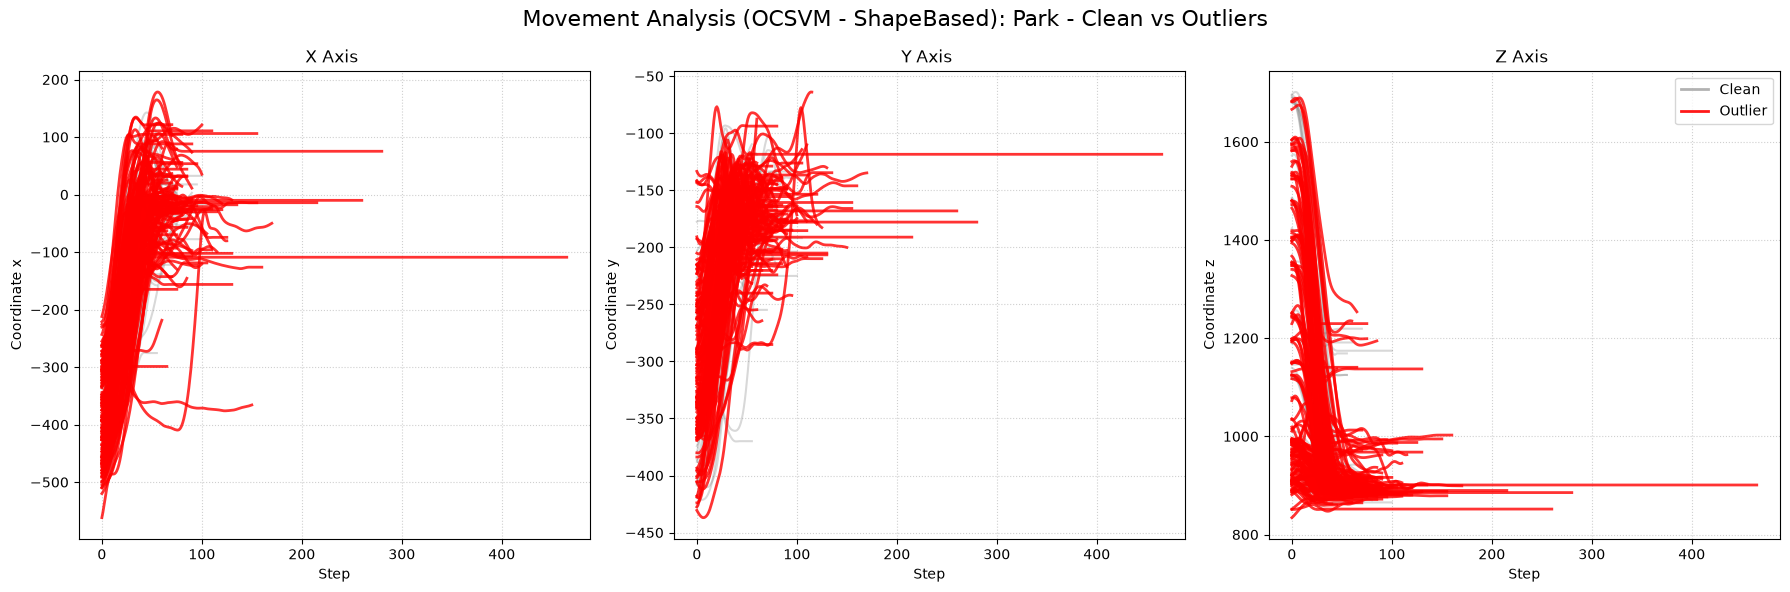

In [ ]:
# plot_movement_data(
#     clean_data=X_movement_clean,
#     outlier_data=X_movement_outliers,
#     target_movement=TARGET_MOVEMENT,
#     algorithm_name=ALGORITHM_NAME,
#     save_fig=Configs.SAVE_PLOTS,
#     save_path=Configs.DESKTOP_PATH,
#     model_representation=MODEL_REPRESENTATION
# )